# LightGBM with scarce training data: 20% of the training basins

`04_lightgbm.ipynb` trained on **all** of each fold's training basins (about 870). Here each model sees only a **random 20%** of them (about 175), while the test basins, test years and scoring stay exactly the same, so the two notebooks are directly comparable.

This is the "training-basin count" experiment that `docs/handoff-modeling.md` lists under "Later". It is where a cluster id is most likely to help: with few training basins, a low-dimensional description of a basin may generalise better than 186 raw attributes.

**How the 20% is drawn.** `cluster_assignments.csv` lists each fold's training basins (`role == train`). For every fold we draw a random 20% of those basins (seeded; `N_DRAWS` independent draws, because one draw of ~175 basins is noisy). The same drawn basins are used by every arm within a draw, so arms differ only in the basin information they receive.

| Arm | Basin information |
| --- | --- |
| `weather` | none beyond the weather itself (the 365-day windows are a rough climate fingerprint, so this arm is not strictly basin-blind) |
| `static` | the raw static attributes |
| `cluster(csv)` | the cluster id **read from `cluster_assignments.csv`**, i.e. clustering fit on *all* of the fold's training basins' attributes |
| `cluster(refit)` | the cluster id from a clustering **refit on only the drawn 20%** (same pipeline as notebook 03), which is how the method would work if only those basins existed |

`cluster(csv)` follows the request to use the assignments file. It uses attribute information from basins the flow model never trains on, so it is a mildly optimistic version of the scarce-data setting. `cluster(refit)` is the strict version. Comparing the two shows how much that matters.

**Rules followed** (same as notebook 04): everything is fit on training basins only and buffer basins are never used; no tuning on test basins (the number of boosting rounds is chosen on held-out spatial blocks *within the drawn basins*, training years only, 100 km buffer); scoring over the test years with the scoring code of `03_knn_donors.ipynb`; per-basin scores saved to `data/results/`. The primary scores use the plain back-transform of `log(q + 0.01)`; bias-corrected `_bc` versions are reported alongside. These choices were fixed before any 20% results were seen.

**Before running:** `data/features/daily_*.parquet` must exist (run notebook 01), and `03_kmeans_clustering.ipynb` must have produced `data/processed/clusters/`.

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import haversine_distances
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
PROCESSED = REPO / "data" / "processed"
SPLITS = PROCESSED / "splits"
STATIC_DIR = PROCESSED / "features"
CLUSTER_DIR = PROCESSED / "clusters"
DAILY = REPO / "data" / "features"          # git-ignored, built by notebook 01
RESULTS = REPO / "data" / "results"
EARTH_RADIUS_KM = 6371.0

## Parameters

`SAMPLE_FRAC`, `HIGH_CARD`, `VAL_FRAC` and `LGB_PARAMS` are identical to notebook 04. The only new settings are the share of training basins and the number of draws. With fewer basins, early stopping on held-out blocks is noisier, so the chosen number of rounds varies more between folds and draws.

In [2]:
TRAIN_BASIN_FRAC = 0.20            # share of each fold's training basins that the models may use
N_DRAWS = 5        # independent random draws of the 20% per fold
SAMPLE_FRAC = 0.20                 # share of training-period days sampled per basin (as in notebook 04)
HIGH_CARD = ["cls_cl_smj", "tec_cl_smj", "fec_cl_smj"]
INCLUDE_CATEGORICAL = True
VAL_FRAC = 0.20                    # share of the drawn basins (whole blocks) held out to choose the number of rounds
MAX_ROUNDS = 800
EARLY_STOP = 40
SEED = 780
N_BOOT = 2000
FOLDS_TO_RUN = None   # None = all folds
WRITE_OUTPUTS = True

LGB_PARAMS = dict(
    objective="regression", learning_rate=0.1, num_leaves=63, min_data_in_leaf=200,
    feature_fraction=0.7, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, max_bin=127,
    num_threads=2, seed=SEED, deterministic=True, force_row_wise=True, verbose=-1,
)

## 1. Inputs and checks

In [3]:
cfg = json.loads((SPLITS / "config.json").read_text())
basins = pd.read_csv(SPLITS / "basins.csv", index_col="gauge_id")
roles = pd.read_csv(SPLITS / "fold_roles.csv")
static_df = pd.read_parquet(STATIC_DIR / "static_attributes.parquet")
groups = json.loads((STATIC_DIR / "feature_groups.json").read_text())
clusters = pd.read_csv(CLUSTER_DIR / "cluster_assignments.csv")
cl_cfg = json.loads((CLUSTER_DIR / "config.json").read_text())

N_FOLDS, LOG_EPS, BUFFER_KM = cfg["n_folds"], cfg["log_eps"], cfg["buffer_km"]
if FOLDS_TO_RUN is None:
    FOLDS_TO_RUN = list(range(N_FOLDS))
K_VALUES = sorted(clusters["k"].unique().tolist())
for s in cfg["subsets"]:
    assert (DAILY / f"daily_{s}.parquet").exists(), f"{DAILY}/daily_{s}.parquet not found: run notebooks/01_preprocessing.ipynb first"
assert not cl_cfg["include_categorical"], "notebook 03 was run with categorical features; refit_clusters below assumes numeric only"


def load_fold(k: int) -> dict:
    r = roles.query("fold == @k").set_index("gauge_id")
    train = r.index[(r["role"] == "train") & basins.loc[r.index, "usable_train"]]
    test = r.index[(r["role"] == "test") & basins.loc[r.index, "usable_test"]]
    return {"train": list(train), "test": list(test)}


folds = {k: load_fold(k) for k in range(N_FOLDS)}
BASIN_IDS = list(static_df.index)
GIDX = pd.Index(BASIN_IDS)
NUMERIC = groups["numeric"]
assert set(BASIN_IDS) == set(basins.index)

for (f, k), g in clusters.groupby(["fold", "k"]):
    assert set(g.loc[g.role == "train", "gauge_id"]) == set(folds[f]["train"]), (f, k)
    assert set(g.loc[g.role == "test", "gauge_id"]) == set(folds[f]["test"]), (f, k)

n_sub = {f: int(round(TRAIN_BASIN_FRAC * len(v["train"]))) for f, v in folds.items()}
print(f"{len(BASIN_IDS)} basins | cluster counts: {K_VALUES} | buffer {BUFFER_KM} km | {N_DRAWS} draw(s) per fold")
pd.DataFrame({f: {"all training basins": len(v["train"]), f"drawn ({TRAIN_BASIN_FRAC:.0%})": n_sub[f], "test": len(v["test"])}
              for f, v in folds.items()}).T.rename_axis("fold")

1208 basins | cluster counts: [3, 4, 6, 8] | buffer 100 km | 5 draw(s) per fold


,all training basins,drawn (20%),test
fold,,,
0,867,173,241
1,905,181,242
2,860,172,242
3,889,178,242
4,875,175,241


## 2. Scoring functions

Copied from Step 2 of `03_knn_donors.ipynb` (as in notebook 04).

In [4]:
def _paired(obs, sim):
    m = np.isfinite(obs) & np.isfinite(sim)
    return obs[m], sim[m]


def nse(obs, sim):
    o, s = _paired(np.asarray(obs, float), np.asarray(sim, float))
    denom = np.sum((o - o.mean()) ** 2)
    return np.nan if len(o) < 2 or denom == 0 else 1 - np.sum((o - s) ** 2) / denom


def kge_parts(obs, sim):
    o, s = _paired(np.asarray(obs, float), np.asarray(sim, float))
    if len(o) < 2 or o.std() == 0 or o.mean() == 0:
        return dict(kge=np.nan, r=np.nan, alpha=np.nan, beta=np.nan)
    r = np.corrcoef(o, s)[0, 1] if s.std() > 0 else 0.0
    alpha, beta = s.std() / o.std(), s.mean() / o.mean()
    return dict(kge=1 - np.sqrt((r - 1) ** 2 + (alpha - 1) ** 2 + (beta - 1) ** 2), r=r, alpha=alpha, beta=beta)


def score(obs, sim):
    lo, ls = np.log(np.asarray(obs, float) + LOG_EPS), np.log(np.clip(np.asarray(sim, float), 0, None) + LOG_EPS)
    return dict(nse=nse(obs, sim), log_nse=nse(lo, ls), **kge_parts(obs, sim))

## 3. Daily data

Identical to notebook 04: a random sample of training-period days with observed flow (`SAMPLE_FRAC`, same seed, so the same days), and **every** observed test-period day for scoring. The 20% restriction applies to basins, not days, so each drawn basin contributes the same number of days as in notebook 04.

In [5]:
all_cols = pq.ParquetFile(DAILY / f"daily_{cfg['subsets'][0]}.parquet").schema_arrow.names
W_COLS = [c for c in all_cols if c not in ("gauge_id", "date", "period", "streamflow", "log_streamflow")]


def read_days(period: str, frac: float | None, seed: int):
    rng = np.random.default_rng(seed)
    W, y, q, g = [], [], [], []
    for s in cfg["subsets"]:
        t = pq.read_table(DAILY / f"daily_{s}.parquet", columns=["gauge_id", "streamflow", "log_streamflow", *W_COLS],
                          filters=[("period", "==", period)])
        flow = t["streamflow"].to_numpy(zero_copy_only=False)
        keep = np.isfinite(flow)
        if frac is not None:
            keep &= rng.random(len(flow)) < frac
        t = t.filter(pa.array(keep))
        g.append(GIDX.get_indexer(t["gauge_id"].to_pandas().astype(str)))
        q.append(t["streamflow"].to_numpy(zero_copy_only=False).astype("float32"))
        y.append(t["log_streamflow"].to_numpy(zero_copy_only=False).astype("float32"))
        W.append(np.column_stack([t[c].to_numpy(zero_copy_only=False).astype("float32") for c in W_COLS]))
        del t
    out = dict(W=np.vstack(W), y=np.concatenate(y), q=np.concatenate(q), g=np.concatenate(g).astype("int32"))
    assert (out["g"] >= 0).all()
    return out


t0 = time.time()
TR = read_days("train", SAMPLE_FRAC, SEED)
TE = read_days("test", None, SEED)
print(f"training-day sample (all basins): {len(TR['y']):,} rows | test: {len(TE['y']):,} rows | {time.time() - t0:.0f}s")

training-day sample (all basins): 1,485,500 rows | test: 4,356,534 rows | 6s


## 4. Feature sets and the two kinds of cluster id

`cluster(csv)` reads the fold's assignments from the file. `cluster(refit)` fits **scaler, PCA and k-means on the drawn basins only** (same recipe and settings as notebook 03, read from `clusters/config.json`) and assigns the drawn and test basins to the nearest of its own centroids. The cluster ids are passed to LightGBM as a categorical feature.

In [6]:
CAT_COLS = [c for c in groups["categorical"] if INCLUDE_CATEGORICAL and c not in HIGH_CARD]
STATIC_COLS = NUMERIC + CAT_COLS
STATIC = static_df.loc[BASIN_IDS, STATIC_COLS].to_numpy("float32")
assert np.isfinite(STATIC).all()
N_W = len(W_COLS)
ARMS = ([("weather", np.nan)] + [("cluster_csv", float(k)) for k in K_VALUES]
        + [("cluster_refit", float(k)) for k in K_VALUES] + [("static", np.nan)])


def cluster_vector_csv(fold: int, k: float) -> np.ndarray:
    g = clusters[(clusters["fold"] == fold) & (clusters["k"] == int(k))]
    v = np.full(len(BASIN_IDS), np.nan, "float32")
    v[GIDX.get_indexer(g["gauge_id"])] = g["cluster"].to_numpy("float32")
    return v


def cluster_vector_refit(train_ids: list[str], other_ids: list[str], k: float) -> np.ndarray:
    # Same pipeline as notebook 03 (StandardScaler -> PCA -> KMeans), fit on train_ids only.
    pipe = Pipeline([
        ("scale", StandardScaler()),
        ("pca", PCA(n_components=cl_cfg["pca_variance"], svd_solver="full", random_state=cl_cfg["seed"])),
        ("kmeans", KMeans(n_clusters=int(k), n_init=cl_cfg["n_init"], random_state=cl_cfg["seed"])),
    ]).fit(static_df.loc[train_ids, NUMERIC])
    ids = list(train_ids) + list(other_ids)
    v = np.full(len(BASIN_IDS), np.nan, "float32")
    v[GIDX.get_indexer(ids)] = pipe.predict(static_df.loc[ids, NUMERIC])
    return v


def design(arm: str, W: np.ndarray, g: np.ndarray, clv: np.ndarray | None):
    if arm == "weather":
        return W, [], list(W_COLS)
    if arm.startswith("cluster"):
        assert np.isfinite(clv[g]).all(), "cluster id missing for a basin used in this fold"
        return np.column_stack([W, clv[g]]), [N_W], list(W_COLS) + ["cluster_id"]
    return np.hstack([W, STATIC[g]]), [N_W + STATIC_COLS.index(c) for c in CAT_COLS], list(W_COLS) + STATIC_COLS

## 5. Choosing the number of rounds inside the drawn basins

As in notebook 04, but within the drawn 20%: whole spatial blocks of the drawn basins (about `VAL_FRAC` of them) are held out, fitting basins within `BUFFER_KM` of a held-out basin are dropped, and the model is stopped early on the held-out blocks' training-period flow. With only ~175 basins this leaves roughly 100 to fit on, so the stopping point is noisier than in notebook 04.

In [7]:
blk = (basins["region"] + "-" + basins["block"].astype(str))
coords = np.radians(basins[["lat", "lon"]].to_numpy())
POS = pd.Series(np.arange(len(basins)), index=basins.index)


def validation_split(train_ids: list[str], seed: int):
    rng = np.random.default_rng(seed)
    b = blk[train_ids]
    val_blocks, n = [], 0
    for name in rng.permutation(b.unique()):
        if n >= VAL_FRAC * len(train_ids):
            break
        val_blocks.append(name)
        n += int((b == name).sum())
    val = [g for g in train_ids if blk[g] in val_blocks]
    rest = [g for g in train_ids if blk[g] not in val_blocks]
    D = haversine_distances(coords[POS[rest]], coords[POS[val]]).min(axis=1) * EARTH_RADIUS_KM
    return [g for g, d in zip(rest, D) if d >= BUFFER_KM], val


def draw_basins(fold: int, draw: int) -> list[str]:
    rng = np.random.default_rng(SEED + 1000 * fold + draw)
    return sorted(rng.choice(folds[fold]["train"], n_sub[fold], replace=False).tolist())


sub = draw_basins(0, 0)
fit_ids, val_ids = validation_split(sub, SEED)
print(f"fold 0, draw 0: {len(sub)} drawn basins -> {len(fit_ids)} to fit, {len(val_ids)} validation, "
      f"{len(sub) - len(fit_ids) - len(val_ids)} dropped by the buffer")
assert set(sub) <= set(folds[0]["train"]) and not set(sub) & set(folds[0]["test"])

fold 0, draw 0: 173 drawn basins -> 138 to fit, 35 validation, 0 dropped by the buffer


## 6. Fit, predict and score

For each fold, draw and arm: (1) fit on the fitting basins and stop early on the validation blocks; (2) refit on **all drawn basins** for that number of rounds; (3) predict every observed test day of the fold's test basins; (4) score each test basin. Results are saved after every fold.

In [8]:
def rows_of(g_all: np.ndarray, ids: list[str]) -> np.ndarray:
    return np.isin(g_all, GIDX.get_indexer(ids))


def predict_chunks(model, X_fn, n, chunk=150_000):
    return np.concatenate([model.predict(X_fn(slice(i, min(i + chunk, n)))) for i in range(0, n, chunk)]).astype("float64")


def run_fold(fold: int, draw: int):
    fo = folds[fold]
    sub = draw_basins(fold, draw)
    assert set(sub) <= set(fo["train"]) and not set(sub) & set(fo["test"])
    fit_ids, val_ids = validation_split(sub, SEED + fold + 100 * draw)
    m_fit, m_val, m_all = (rows_of(TR["g"], ids) for ids in (fit_ids, val_ids, sub))
    m_te = rows_of(TE["g"], fo["test"])
    Wte, yte, qte, gte = TE["W"][m_te], TE["y"][m_te], TE["q"][m_te], TE["g"][m_te]
    score_rows, run_rows, imp_rows = [], [], []

    for arm, k in ARMS:
        t0 = time.time()
        clv = (cluster_vector_csv(fold, k) if arm == "cluster_csv"
               else cluster_vector_refit(sub, fo["test"], k) if arm == "cluster_refit" else None)
        Xf, cat, names = design(arm, TR["W"][m_fit], TR["g"][m_fit], clv)
        Xv, _, _ = design(arm, TR["W"][m_val], TR["g"][m_val], clv)
        dfit = lgb.Dataset(Xf, TR["y"][m_fit], categorical_feature=cat, feature_name=names, free_raw_data=False)
        dval = lgb.Dataset(Xv, TR["y"][m_val], reference=dfit, categorical_feature=cat, feature_name=names)
        stage1 = lgb.train(LGB_PARAMS, dfit, MAX_ROUNDS, valid_sets=[dval], callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False)])
        best = max(stage1.best_iteration, 1)
        resid = TR["y"][m_val] - stage1.predict(Xv, num_iteration=best)     # held-out validation residuals, training years only
        smear = float(np.mean(np.exp(resid)))
        del Xf, Xv, dfit, dval

        Xa, cat, names = design(arm, TR["W"][m_all], TR["g"][m_all], clv)
        model = lgb.train(LGB_PARAMS, lgb.Dataset(Xa, TR["y"][m_all], categorical_feature=cat, feature_name=names), best)
        n_rows = len(Xa)
        del Xa

        pred_log = predict_chunks(model, lambda s: design(arm, Wte[s], gte[s], clv)[0], len(yte))
        q_naive = np.clip(np.exp(pred_log) - LOG_EPS, 0, None)
        q_bc = np.clip(smear * np.exp(pred_log) - LOG_EPS, 0, None)
        arm_nse = []
        for g_idx in np.unique(gte):
            m = gte == g_idx
            gid = BASIN_IDS[g_idx]
            s_n, s_b = score(qte[m], q_naive[m]), score(qte[m], q_bc[m])
            arm_nse.append(s_n["nse"])
            score_rows.append({"fold": fold, "draw": draw, "gauge_id": gid, "region": basins.at[gid, "region"], "arm": arm,
                               "n_clusters": k, **s_n, "nse_bc": s_b["nse"], "log_nse_bc": s_b["log_nse"], "kge_bc": s_b["kge"],
                               "nse_logspace": nse(yte[m], pred_log[m])})
        run_rows.append({"fold": fold, "draw": draw, "arm": arm, "n_clusters": k, "n_features": len(names),
                         "n_fit_basins": len(fit_ids), "n_train_basins": len(sub), "n_train_rows": n_rows,
                         "best_iter": best, "smear": smear, "seconds": round(time.time() - t0, 1)})
        imp = pd.Series(model.feature_importance("gain"), index=names)
        imp_rows.append(pd.DataFrame({"fold": fold, "draw": draw, "arm": arm, "n_clusters": k, "feature": imp.index,
                                      "gain_share": (imp / imp.sum()).to_numpy()}))
        print(f"  fold {fold} draw {draw} {arm:13s} k={'' if np.isnan(k) else int(k)!s:2s} rounds={best:3d} "
              f"median NSE={np.nanmedian(arm_nse):.3f} ({time.time() - t0:.0f}s)", flush=True)
    return pd.DataFrame(score_rows), pd.DataFrame(run_rows), pd.concat(imp_rows, ignore_index=True)


all_scores, all_runs, all_imps = [], [], []
t_start = time.time()
for fold in FOLDS_TO_RUN:
    for draw in range(N_DRAWS):
        print(f"fold {fold}, draw {draw}: {n_sub[fold]} of {len(folds[fold]['train'])} training basins, {len(folds[fold]['test'])} test basins")
        s, r, i = run_fold(fold, draw)
        all_scores.append(s); all_runs.append(r); all_imps.append(i)
    if WRITE_OUTPUTS:
        RESULTS.mkdir(parents=True, exist_ok=True)
        pd.concat(all_scores).to_csv(RESULTS / "lightgbm_small_scores.csv", index=False)
        pd.concat(all_runs).to_csv(RESULTS / "lightgbm_small_runs.csv", index=False)
        pd.concat(all_imps).to_csv(RESULTS / "lightgbm_small_importance.csv", index=False)
print(f"done in {(time.time() - t_start) / 60:.1f} min")
scores = pd.concat(all_scores, ignore_index=True)
runs = pd.concat(all_runs, ignore_index=True)
imps = pd.concat(all_imps, ignore_index=True)

fold 0, draw 0: 173 of 867 training basins, 241 test basins


  fold 0 draw 0 weather       k=   rounds= 61 median NSE=0.217 (4s)


  fold 0 draw 0 cluster_csv   k=3  rounds= 52 median NSE=0.208 (4s)


  fold 0 draw 0 cluster_csv   k=4  rounds= 75 median NSE=0.219 (5s)


  fold 0 draw 0 cluster_csv   k=6  rounds= 50 median NSE=0.198 (4s)


  fold 0 draw 0 cluster_csv   k=8  rounds= 41 median NSE=0.202 (4s)


... (266 outputs left out)

  fold 4 draw 4 cluster_refit k=6  rounds= 62 median NSE=0.199 (5s)


  fold 4 draw 4 cluster_refit k=8  rounds= 92 median NSE=0.240 (6s)


  fold 4 draw 4 static        k=   rounds=125 median NSE=0.225 (24s)


done in 25.3 min


## 7. Results

### Sanity checks and labels

Each test basin must be scored once per arm and draw, and only the fold's own test basins may appear. Because every basin is a test basin in exactly one fold, all analyses below first **average each basin's score over the draws**, giving one value per basin and arm.

In [9]:
def add_label(df):
    k = df["n_clusters"].fillna(0).astype(int).astype(str)
    df["arm_label"] = np.select([df["arm"] == "cluster_csv", df["arm"] == "cluster_refit"],
                                ["cluster(csv) k=" + k, "cluster(refit) k=" + k], default=df["arm"])
    return df

for d in (scores, runs, imps):
    add_label(d)
ORDER = (["weather"] + [f"cluster(csv) k={k}" for k in K_VALUES] + [f"cluster(refit) k={k}" for k in K_VALUES] + ["static"])

exp_n = sum(len(folds[f]["test"]) for f in FOLDS_TO_RUN)
cnt = scores.groupby("arm_label").size()
assert (cnt == exp_n * N_DRAWS).all(), cnt
for f in FOLDS_TO_RUN:
    assert set(scores.loc[scores.fold == f, "gauge_id"]) == set(folds[f]["test"])
print(f"{exp_n} test basins x {len(ORDER)} arms x {N_DRAWS} draws; every test basin scored once per arm and draw")

METRICS = ["nse", "kge", "log_nse", "r", "alpha", "beta", "nse_bc", "kge_bc", "log_nse_bc"]
bs = scores.groupby(["gauge_id", "arm_label"])[METRICS].mean().reset_index().merge(
    basins[["region"]], left_on="gauge_id", right_index=True)
runs.pivot_table(index="arm_label", values=["best_iter", "smear", "n_train_basins", "n_fit_basins", "seconds"], aggfunc="mean").loc[ORDER].round(1)

1208 test basins x 10 arms x 5 draws; every test basin scored once per arm and draw


,best_iter,n_fit_basins,n_train_basins,seconds,smear
arm_label,,,,,
weather,66.8,134.8,175.8,4.6,1.9
cluster(csv) k=3,60.6,134.8,175.8,4.5,2.0
cluster(csv) k=4,81.1,134.8,175.8,5.3,1.9
cluster(csv) k=6,63.7,134.8,175.8,4.6,1.9
cluster(csv) k=8,64.1,134.8,175.8,4.6,2.0
cluster(refit) k=3,67.1,134.8,175.8,4.8,2.0
cluster(refit) k=4,60.2,134.8,175.8,4.5,1.9
cluster(refit) k=6,69.4,134.8,175.8,4.8,1.9
cluster(refit) k=8,65.5,134.8,175.8,4.7,1.9


### Median score across test basins (20% of training basins)

Scores are averaged over draws per basin, then the median is taken across basins. The second table shows how much a median moves from one draw to another, which is the noise to keep in mind when comparing arms: differences smaller than this spread are not informative.

In [10]:
def summarize(df, cols):
    return df.groupby("arm_label")[cols].median().loc[ORDER].round(3)

print("All test basins")
display(summarize(bs, ["nse", "kge", "log_nse", "nse_bc", "kge_bc", "log_nse_bc"]))
for region, g in bs.groupby("region"):
    print(f"{region} test basins (n={g.gauge_id.nunique()})")
    display(summarize(g, ["nse", "kge", "log_nse", "r", "alpha", "beta"]))

if N_DRAWS > 1:
    per_draw = scores.groupby(["draw", "arm_label"])[["nse", "log_nse"]].median().unstack("draw")
    spread = pd.concat({m: per_draw[m].agg(["min", "max"], axis=1).round(3) for m in ["nse", "log_nse"]}, axis=1)
    print("Range of the median across draws (min, max)")
    display(spread.loc[ORDER])

All test basins


,nse,kge,log_nse,nse_bc,kge_bc,log_nse_bc
arm_label,,,,,,
weather,0.161,0.018,0.395,0.174,0.089,0.159
cluster(csv) k=3,0.167,0.027,0.400,0.172,0.077,0.151
cluster(csv) k=4,0.170,0.032,0.396,0.174,0.093,0.151
cluster(csv) k=6,0.162,0.017,0.378,0.170,0.089,0.165
cluster(csv) k=8,0.162,0.024,0.383,0.166,0.093,0.155
cluster(refit) k=3,0.167,0.028,0.399,0.166,0.087,0.150
cluster(refit) k=4,0.170,0.031,0.398,0.176,0.092,0.143
cluster(refit) k=6,0.171,0.035,0.384,0.175,0.097,0.153
cluster(refit) k=8,0.173,0.033,0.391,0.175,0.095,0.166


AUS test basins (n=541)


,nse,kge,log_nse,r,alpha,beta
arm_label,,,,,,
weather,0.140,-0.067,0.413,0.568,0.216,0.603
cluster(csv) k=3,0.138,-0.074,0.431,0.573,0.211,0.578
cluster(csv) k=4,0.146,-0.078,0.407,0.572,0.228,0.588
cluster(csv) k=6,0.148,-0.072,0.403,0.575,0.225,0.586
cluster(csv) k=8,0.137,-0.068,0.426,0.570,0.223,0.580
cluster(refit) k=3,0.144,-0.069,0.429,0.573,0.232,0.582
cluster(refit) k=4,0.146,-0.071,0.422,0.573,0.222,0.588
cluster(refit) k=6,0.145,-0.069,0.412,0.574,0.232,0.601
cluster(refit) k=8,0.149,-0.057,0.426,0.574,0.231,0.581


US test basins (n=667)


,nse,kge,log_nse,r,alpha,beta
arm_label,,,,,,
weather,0.188,0.092,0.374,0.586,0.349,0.602
cluster(csv) k=3,0.199,0.114,0.378,0.597,0.357,0.606
cluster(csv) k=4,0.196,0.114,0.384,0.600,0.355,0.624
cluster(csv) k=6,0.181,0.083,0.351,0.596,0.340,0.602
cluster(csv) k=8,0.189,0.089,0.346,0.603,0.347,0.601
cluster(refit) k=3,0.198,0.108,0.389,0.600,0.363,0.606
cluster(refit) k=4,0.201,0.107,0.387,0.595,0.356,0.614
cluster(refit) k=6,0.195,0.096,0.364,0.606,0.350,0.611
cluster(refit) k=8,0.195,0.105,0.355,0.606,0.357,0.618


Range of the median across draws (min, max)


nse        log_nse       
                      min    max     min    max
arm_label                                      
weather             0.142  0.178   0.397  0.437
cluster(csv) k=3    0.151  0.184   0.396  0.445
cluster(csv) k=4    0.156  0.180   0.393  0.434
cluster(csv) k=6    0.137  0.179   0.385  0.444
cluster(csv) k=8    0.149  0.182   0.387  0.447
cluster(refit) k=3  0.150  0.184   0.391  0.442
cluster(refit) k=4  0.152  0.193   0.387  0.443
cluster(refit) k=6  0.150  0.194   0.400  0.438
cluster(refit) k=8  0.155  0.182   0.415  0.449
static              0.154  0.205   0.418  0.485

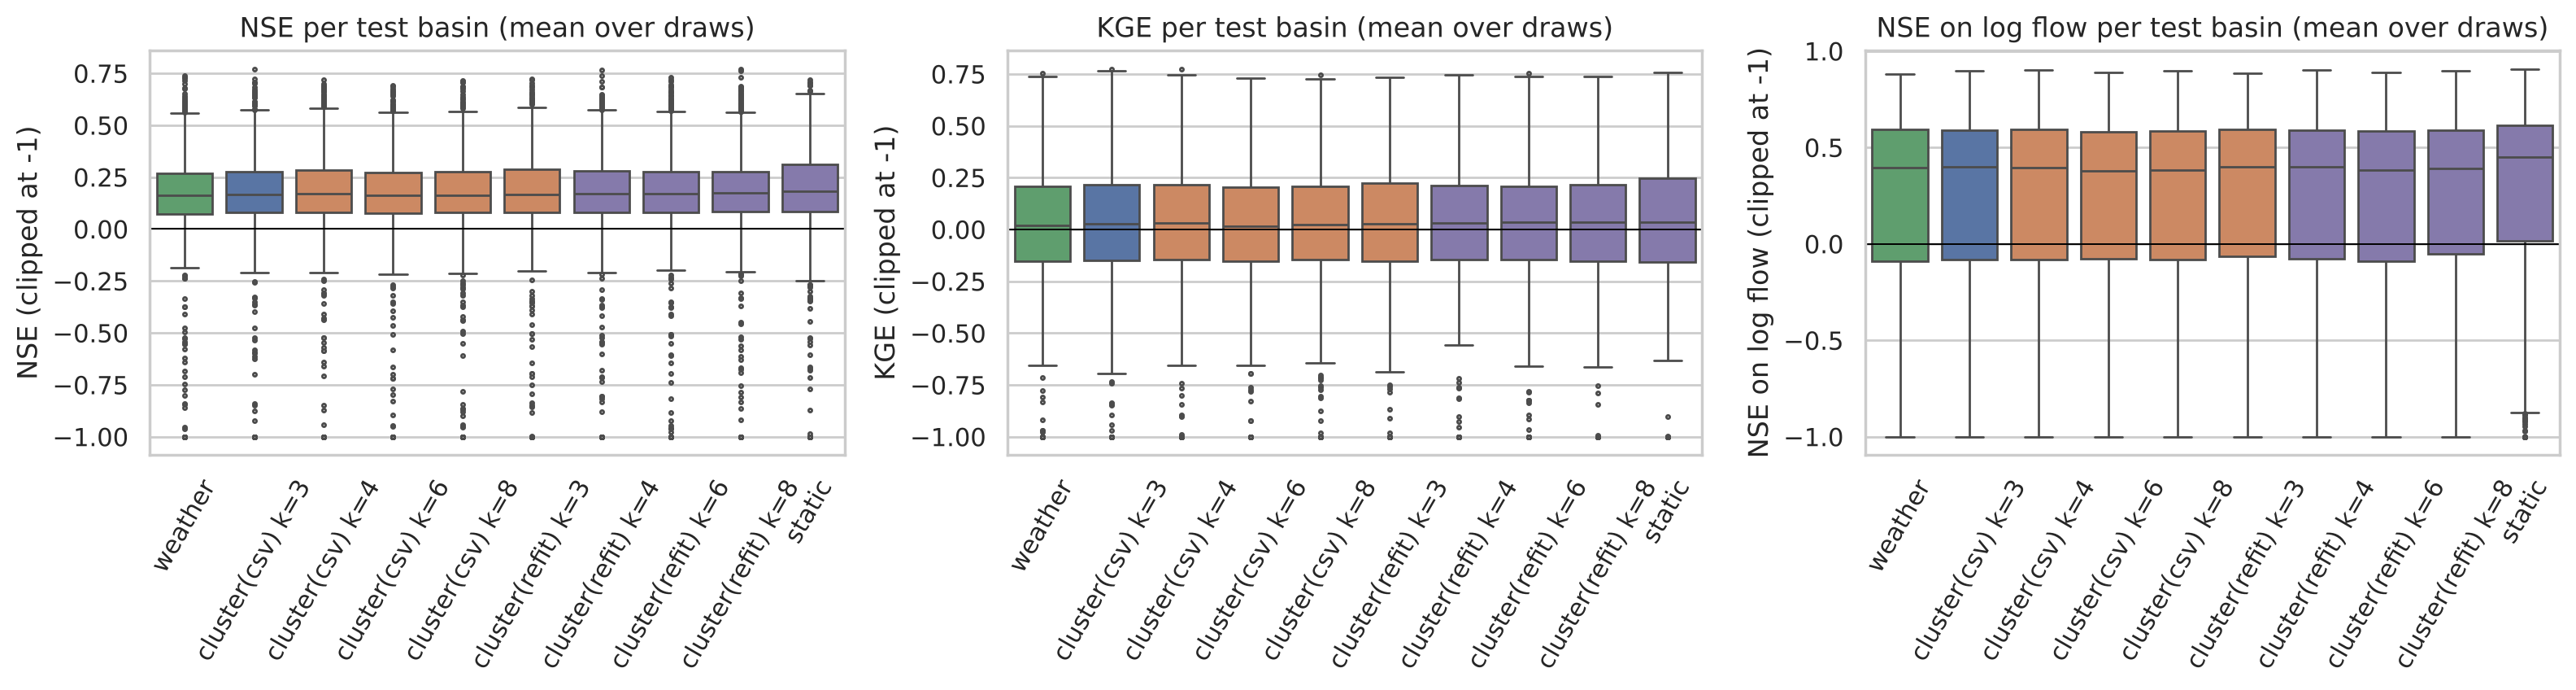

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
pal = {"weather": "C0", "static": "C2"}
colors = [pal.get(a, "C1" if "csv" in a else "C4") for a in ORDER]
for ax, (m, lab) in zip(axes, [("nse", "NSE"), ("kge", "KGE"), ("log_nse", "NSE on log flow")]):
    sns.boxplot(data=bs.assign(v=bs[m].clip(lower=-1)), x="arm_label", y="v", order=ORDER, palette=colors, hue="arm_label",
                legend=False, fliersize=1.5, linewidth=1, ax=ax)
    ax.set(title=f"{lab} per test basin (mean over draws)", xlabel="", ylabel=lab + " (clipped at -1)")
    ax.tick_params(axis="x", rotation=60)
    ax.axhline(0, color="black", lw=0.7)
plt.tight_layout()
plt.show()

### Paired comparisons across basins

Same method as notebook 04: for each test basin the difference between two arms' scores, summarised by the median across basins with a 95% bootstrap interval (resampling basins). The comparisons that matter here:

- `cluster(csv) − static` and `cluster(refit) − static`: does a cluster id beat the raw attributes when training basins are scarce? (Notebook 04 found it did not with all basins.)
- `cluster(refit) − weather`: does basin information help at all?
- `cluster(refit) − cluster(csv)`: how much does it matter whether the clustering saw only the drawn basins?
- `static − weather`.

In [12]:
def pivot(metric):
    return bs.pivot(index="gauge_id", columns="arm_label", values=metric)


def boot_median_diff(d: pd.Series, n=N_BOOT, seed=SEED):
    d = d.dropna().to_numpy()
    rng = np.random.default_rng(seed)
    meds = np.median(d[rng.integers(0, len(d), (n, len(d)))], axis=1)
    return np.median(d), *np.percentile(meds, [2.5, 97.5])


METRIC_LABELS = [("nse", "NSE"), ("kge", "KGE"), ("log_nse", "NSE on log flow")]
pairs = ([(f"cluster(csv) k={k}", "static") for k in K_VALUES] + [(f"cluster(refit) k={k}", "static") for k in K_VALUES]
         + [(f"cluster(csv) k={k}", "weather") for k in K_VALUES] + [(f"cluster(refit) k={k}", "weather") for k in K_VALUES]
         + [(f"cluster(refit) k={k}", f"cluster(csv) k={k}") for k in K_VALUES] + [("static", "weather")])
comp = []
for metric, lab in METRIC_LABELS:
    P = pivot(metric)
    for a, b in pairs:
        med, lo, hi = boot_median_diff(P[a] - P[b])
        comp.append({"metric": lab, "comparison": f"{a} - {b}", "median diff": med, "95% CI low": lo, "95% CI high": hi})
comp = pd.DataFrame(comp)
comp.pivot_table(index="comparison", columns="metric", values=["median diff", "95% CI low", "95% CI high"], sort=False).round(3)

median diff                         \
metric                                        NSE    KGE NSE on log flow   
comparison                                                                 
cluster(csv) k=3 - static                  -0.006 -0.000          -0.017   
cluster(csv) k=4 - static                  -0.005 -0.001          -0.018   
cluster(csv) k=6 - static                  -0.009 -0.012          -0.029   
cluster(csv) k=8 - static                  -0.008 -0.005          -0.024   
cluster(refit) k=3 - static                -0.005 -0.003          -0.014   
cluster(refit) k=4 - static                -0.006 -0.002          -0.022   
cluster(refit) k=6 - static                -0.004 -0.002          -0.024   
cluster(refit) k=8 - static                -0.005 -0.003          -0.016   
cluster(csv) k=3 - weather                  0.003  0.005           0.006   
cluster(csv) k=4 - weather                  0.004  0.007           0.002   
cluster(csv) k=6 - weather                  0.001  0.000          -0.004   
cluster(csv) k=8 - weather                  0.005  0.006          -0.005   
cluster(refit) k=3 - weather                0.007  0.010           0.005   
cluster(refit) k=4 - weather                0.009  0.012           0.006   
cluster(refit) k=6 - weather                0.006  0.005           0.000   
cluster(refit) k=8 - weather                0.008  0.012           0.007   
cluster(refit) k=3 - cluster(csv) k=3       0.001  0.000          -0.002   
cluster(refit) k=4 - cluster(csv) k=4       0.002  0.001           0.003   
cluster(refit) k=6 - cluster(csv) k=6       0.003  0.004           0.003   
cluster(refit) k=8 - cluster(csv) k=8       0.002  0.001           0.008   
static - weather                            0.011  0.009           0.025   

                                      95% CI low                         \
metric                                       NSE    KGE NSE on log flow   
comparison                                                                
cluster(csv) k=3 - static                 -0.011 -0.011          -0.026   
cluster(csv) k=4 - static                 -0.009 -0.010          -0.030   
cluster(csv) k=6 - static                 -0.015 -0.020          -0.039   
cluster(csv) k=8 - static                 -0.011 -0.013          -0.035   
cluster(refit) k=3 - static               -0.010 -0.009          -0.025   
cluster(refit) k=4 - static               -0.010 -0.008          -0.033   
cluster(refit) k=6 - static               -0.009 -0.013          -0.033   
cluster(refit) k=8 - static               -0.011 -0.011          -0.029   
cluster(csv) k=3 - weather                 0.001  0.003           0.004   
cluster(csv) k=4 - weather                 0.003  0.004          -0.002   
cluster(csv) k=6 - weather                 0.000 -0.002          -0.008   
cluster(csv) k=8 - weather                 0.002  0.001          -0.012   
cluster(refit) k=3 - weather               0.006  0.009           0.002   
cluster(refit) k=4 - weather               0.008  0.009           0.002   
cluster(refit) k=6 - weather               0.004  0.002          -0.005   
cluster(refit) k=8 - weather               0.007  0.008           0.001   
cluster(refit) k=3 - cluster(csv) k=3     -0.000 -0.002          -0.004   
cluster(refit) k=4 - cluster(csv) k=4      0.000 -0.002           0.000   
cluster(refit) k=6 - cluster(csv) k=6      0.001  0.001          -0.001   
cluster(refit) k=8 - cluster(csv) k=8      0.000 -0.003           0.005   
static - weather                           0.007  0.001           0.015   

                                      95% CI high                         
metric                                        NSE    KGE NSE on log flow  
comparison                                                                
cluster(csv) k=3 - static                  -0.002  0.009          -0.009  
cluster(csv) k=4 - static                  -0.000  0.008          -0.011  
cluster(csv) k=6 - static            

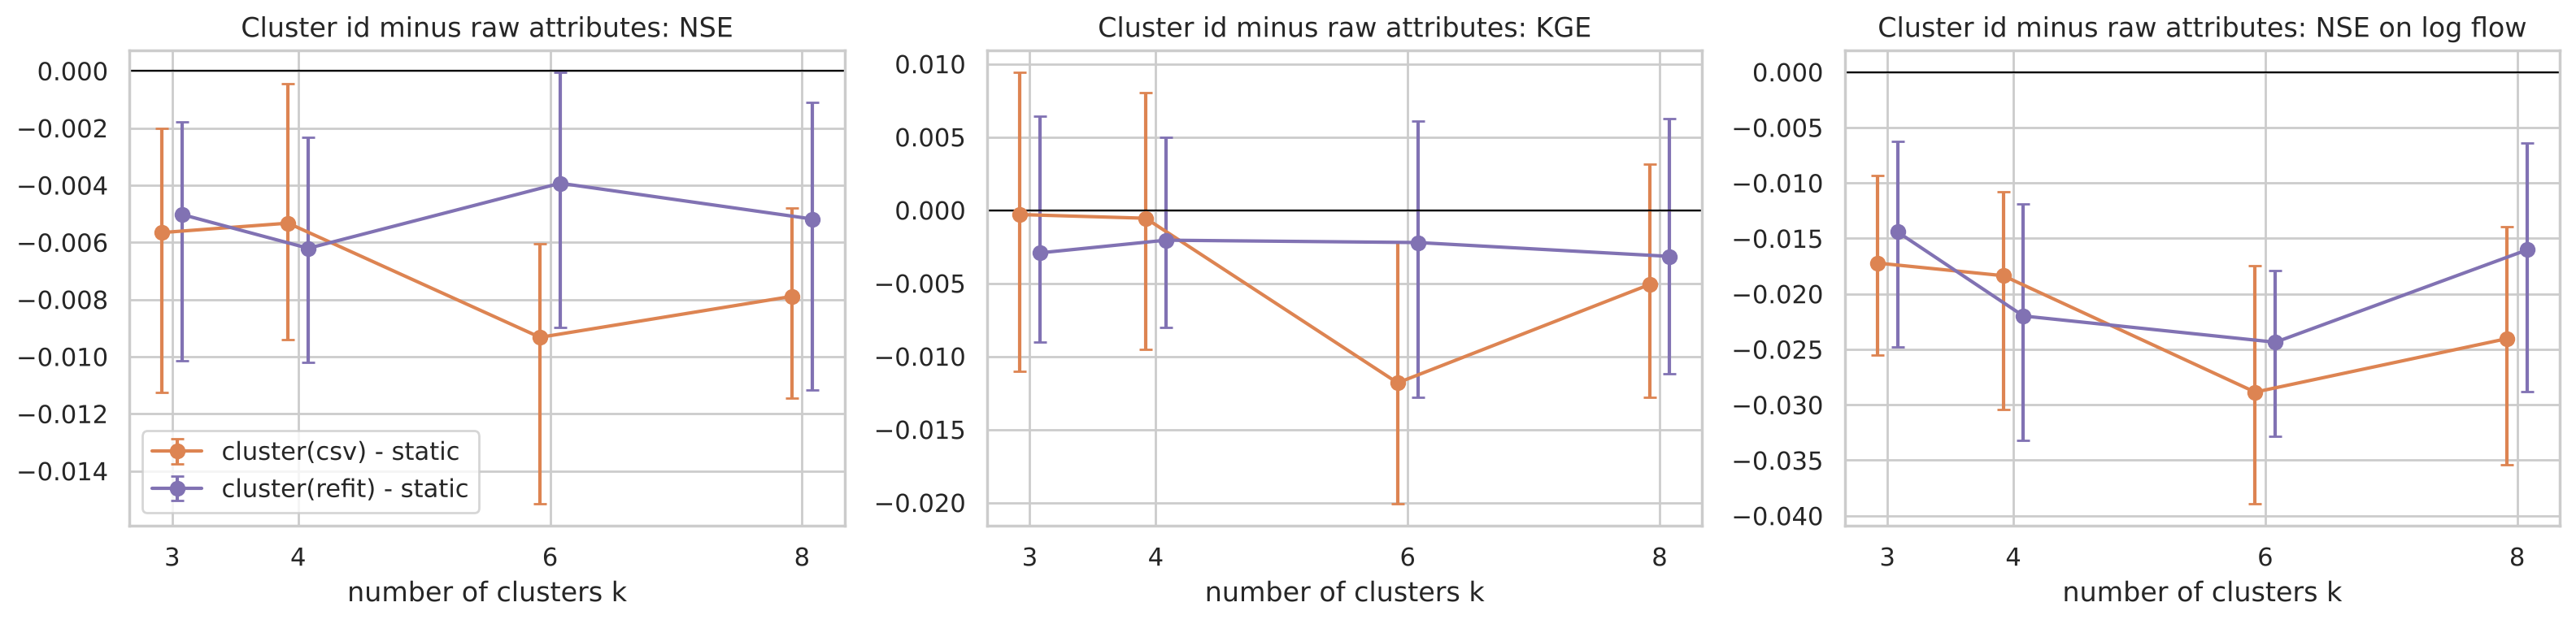

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (_, lab) in zip(axes, METRIC_LABELS):
    for kind, color, dx in [("csv", "C1", -0.08), ("refit", "C4", 0.08)]:
        s = comp[(comp.metric == lab) & comp["comparison"].str.startswith(f"cluster({kind})") & comp["comparison"].str.endswith("- static")].copy()
        s["k"] = s["comparison"].str.extract(r"k=(\d+)")[0].astype(float)
        ax.errorbar(s["k"] + dx, s["median diff"], yerr=[s["median diff"] - s["95% CI low"], s["95% CI high"] - s["median diff"]],
                    fmt="o-", color=color, capsize=3, label=f"cluster({kind}) - static")
    ax.axhline(0, color="black", lw=0.8)
    ax.set(title=f"Cluster id minus raw attributes: {lab}", xlabel="number of clusters k", xticks=K_VALUES)
axes[0].legend()
plt.tight_layout()
plt.show()

### Scarce versus full training data

`data/results/lightgbm_scores.csv` (from `04_lightgbm.ipynb`) holds the same test basins scored by models trained on **all** training basins. The table puts the two side by side: the change in each arm's median when 80% of the training basins are removed. The full-data `cluster` arm corresponds to `cluster(csv)` here, since both read the assignments file.

In [14]:
full_path = RESULTS / "lightgbm_scores.csv"
if full_path.exists():
    full = pd.read_csv(full_path)
    full["arm_label"] = np.select([full["arm"] == "cluster"], ["cluster(csv) k=" + full["n_clusters"].fillna(0).astype(int).astype(str)], default=full["arm"])
    cols = ["nse", "kge", "log_nse"]
    fm = full.groupby("arm_label")[cols].median()
    sm = bs.groupby("arm_label")[cols].median()
    idx = [a for a in ORDER if a in fm.index]
    out = pd.concat({"all training basins": fm.loc[idx], "20% of training basins": sm.loc[idx], "change": sm.loc[idx] - fm.loc[idx]}, axis=1)
    display(out.round(3))
else:
    print("data/results/lightgbm_scores.csv not found; run 04_lightgbm.ipynb to enable this comparison.")

all training basins                20% of training basins  \
                                 nse    kge log_nse                    nse   
arm_label                                                                    
weather                        0.209  0.087   0.478                  0.161   
cluster(csv) k=3               0.199  0.067   0.486                  0.167   
cluster(csv) k=4               0.205  0.086   0.489                  0.170   
cluster(csv) k=6               0.196  0.065   0.478                  0.162   
cluster(csv) k=8               0.201  0.075   0.482                  0.162   
static                         0.213  0.092   0.521                  0.181   

                                change                 
                    kge log_nse    nse    kge log_nse  
arm_label                                              
weather           0.018   0.395 -0.048 -0.069  -0.083  
cluster(csv) k=3  0.027   0.400 -0.032 -0.040  -0.086  
cluster(csv) k=4  0.032   0.396 -0.035 -0.054  -0.093  
cluster(csv) k=6  0.017   0.378 -0.033 -0.048  -0.100  
cluster(csv) k=8  0.024   0.383 -0.039 -0.051  -0.099  
static            0.035   0.451 -0.032 -0.057  -0.070

### What do the models rely on?

Share of total split gain going to basin information versus weather, averaged over folds and draws.

In [15]:
imps["group"] = np.where(imps["feature"].isin(W_COLS), "weather", "basin information")
grp = imps.groupby(["arm_label", "fold", "draw", "group"])["gain_share"].sum().unstack("group").fillna(0).groupby("arm_label").mean().loc[ORDER]
display(grp.round(3))

group,basin information,weather
arm_label,,
weather,0.000,1.000
cluster(csv) k=3,0.058,0.942
cluster(csv) k=4,0.095,0.905
cluster(csv) k=6,0.175,0.825
cluster(csv) k=8,0.250,0.750
cluster(refit) k=3,0.061,0.939
cluster(refit) k=4,0.096,0.904
cluster(refit) k=6,0.187,0.813
cluster(refit) k=8,0.225,0.775


## 8. Notes

- **Files written:** `data/results/lightgbm_small_scores.csv` (per-basin, per-draw scores; same layout as notebook 04's file plus a `draw` column and the two cluster arms `cluster_csv` and `cluster_refit`), `lightgbm_small_runs.csv` and `lightgbm_small_importance.csv`.
- **Noise:** with ~175 training basins per fold and `N_DRAWS` draws, differences of a few hundredths between arms can come from which basins were drawn. Increase `N_DRAWS` to tighten this; the paired intervals above resample test basins but not the draws.
- **Other training-set sizes:** change `TRAIN_BASIN_FRAC` (the handoff suggests 25, 50, 100 and all basins; 20% is about 175).
- **Fixed settings:** only the number of rounds is chosen from data; all other LightGBM settings are the same as in notebook 04 and were not tuned for the smaller set.